In [1]:
#%pip install xlrd
#%pip install plotly
#%pip install nbformat

In [2]:
import pandas as pd
import re # Imports the regex (regular expressions) library to help with string formatting manipulation.
import numpy as np
import plotly.express as px

url = "GSAF5.xls"
jaws = pd.read_excel(url)
display(jaws)

,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7120,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,Roebuck Bay,Diving,male,M,NaN,...,NaN,"H. Taunton; N. Bartlett, p. 234",ND-0005-RoebuckBay.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0005,ND.0005,6.0,NaN,NaN
7121,Before 1903,0.0,Unprovoked,AUSTRALIA,Western Australia,NaN,Pearl diving,Ahmun,M,NaN,...,NaN,"H. Taunton; N. Bartlett, pp. 233-234",ND-0004-Ahmun.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0004,ND.0004,5.0,NaN,NaN
7122,1900-1905,0.0,Unprovoked,USA,North Carolina,Ocracoke Inlet,Swimming,Coast Guard personnel,M,NaN,...,NaN,"F. Schwartz, p.23; C. Creswell, GSAF",ND-0003-Ocracoke_1900-1905.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0003,ND.0003,4.0,NaN,NaN
7123,1883-1889,0.0,Unprovoked,PANAMA,NaN,"Panama Bay 8ºN, 79ºW",NaN,Jules Patterson,M,NaN,...,NaN,"The Sun, 10/20/1938",ND-0002-JulesPatterson.pdf,http://sharkattackfile.net/spreadsheets/pdf_di...,http://sharkattackfile.net/spreadsheets/pdf_di...,ND.0002,ND.0002,3.0,NaN,NaN


In [3]:
print(jaws.columns)

Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'],
      dtype='object')


In [4]:
print(jaws.shape)
print(jaws.columns)
print(jaws.dtypes)
print(jaws.info)
print(jaws.describe)
"""
Columns name format :
Date is an object : OK, but 1/ we have to clean all words 2/ we have to convert month(letter)... too many operation to do on the date itself. do we have to avoid this column ? ;
Year is a float, it must be an integer;
Type is is an object : OK;
Country is an object : OK;

Date               object KO too many operation to do on the date itself ; eject after seen if year is complete
Year              float64 OK convert in int
Type               object OK
Country            object OK
State              object KO  see if there is Countries inside ?
Location           object KO
Activity           object OK
Name               object KO
Sex                object OK
Age                object KO
Injury             object KO
Fatal Y/N          object OK
Time               object KO
Species            object OK
Source             object KO
pdf                object KO
href formula       object OK
href               object KO
Case Number        object OK convert i, as a date and merge date and year columns inside
Case Number.1      object KO
original order    float64 OK convert in int
Unnamed: 21        object KO
Unnamed: 22        object KO


Rows
We keep only the 50 years"""

(7125, 23)
Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'],
      dtype='object')
Date               object
Year              float64
Type               object
Country            object
State              object
Location           object
Activity           object
Name               object
Sex                object
Age                object
Injury             object
Fatal Y/N          object
Time               object
Species            object
Source             object
pdf                object
href formula       object
href               object
Case Number        object
Case Number.1      object
original order    float64
Unnamed: 21        object
Unnamed: 22        object
dtype: object
<bound method DataFrame.info of                  Date    Year        Typ

'\nColumns name format :\nDate is an object : OK, but 1/ we have to clean all words 2/ we have to convert month(letter)... too many operation to do on the date itself. do we have to avoid this column ? ;\nYear is a float, it must be an integer;\nType is is an object : OK;\nCountry is an object : OK;\n\nDate               object KO too many operation to do on the date itself ; eject after seen if year is complete\nYear              float64 OK convert in int\nType               object OK\nCountry            object OK\nState              object KO  see if there is Countries inside ?\nLocation           object KO\nActivity           object OK\nName               object KO\nSex                object OK\nAge                object KO\nInjury             object KO\nFatal Y/N          object OK\nTime               object KO\nSpecies            object OK\nSource             object KO\npdf                object KO\nhref formula       object OK\nhref               object KO\nCase Number        obj

In [5]:
# Check for duplicates and missing values

print(jaws.duplicated().sum())
display(jaws.isna().sum())

0


Date                 0
Year                 2
Type                18
Country             50
State              487
Location           567
Activity           583
Name               218
Sex                578
Age               2994
Injury              36
Fatal Y/N          561
Time              3527
Species           3131
Source              20
pdf                326
href formula       331
href               329
Case Number        327
Case Number.1      328
original order     326
Unnamed: 21       7124
Unnamed: 22       7123
dtype: int64

In [6]:
# Transform them into snake_case and lower case to avoid any future issues with column names
jaws.columns = (
    jaws.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

display(jaws.columns)

Index(['date', 'year', 'type', 'country', 'state', 'location', 'activity',
       'name', 'sex', 'age', 'injury', 'fatal_y/n', 'time', 'species',
       'source', 'pdf', 'href_formula', 'href', 'case_number', 'case_number.1',
       'original_order', 'unnamed:_21', 'unnamed:_22'],
      dtype='object')

In [7]:
print("\ndate",jaws["date"].value_counts())
print("\nyear",jaws["year"].value_counts())
print("\ncountry",jaws["country"].value_counts())
print("\nlocation",jaws["location"].value_counts())
print("\nactivity",jaws["activity"].value_counts())
print("\nsex",jaws["sex"].value_counts())
print("\nage",jaws["age"].value_counts())
print("\ninjury",jaws["injury"].value_counts())
print("\nfatal_y/n",jaws["fatal_y/n"].value_counts())
print("\ntime",jaws["time"].value_counts())
print("\nspecies",jaws["species"].value_counts())
print("\nsource",jaws["source"].value_counts())
print("\npdf",jaws["pdf"].value_counts())
print("\nhref_formula",jaws["href_formula"].value_counts())
print("\nhref",jaws["href"].value_counts())
print("\ncase_number",jaws["case_number"].value_counts())
print("\ncase_number.1",jaws["case_number.1"].value_counts())
print("\noriginal_order",jaws["original_order"].value_counts())
print("\nunnamed:_21",jaws["unnamed:_21"].value_counts())
print("\nunnamed:_22",jaws["unnamed:_22"].value_counts())


date date
1957           9
1942           8
1958           7
1956           6
No date        6
              ..
27-Aug-2001    1
29-Aug-2001    1
31-Aug-2001    1
01-Sep-2001    1
1845-1853      1
Name: count, Length: 6159, dtype: int64

year year
2015.0    143
2017.0    141
2016.0    133
0.0       129
2011.0    128
         ... 
1784.0      1
1834.0      1
1780.0      1
1779.0      1
1816.0      1
Name: count, Length: 261, dtype: int64

country country
USA                   2597
AUSTRALIA             1482
SOUTH AFRICA           597
NEW ZEALAND            144
BAHAMAS                136
                      ... 
US Virgin Islands        1
Seychelles               1
GRAND CAYMAN             1
ST. MAARTIN              1
CEYLON (SRI LANKA)       1
Name: count, Length: 257, dtype: int64

location location
New Smyrna Beach, Volusia County       191
Daytona Beach, Volusia County           31
Ponce Inlet, Volusia County             28
Myrtle Beach, Horry County              22
Melbourne Beac

In [8]:
"""The "date" column cleaning starts here"""

'The "date" column cleaning starts here'

In [9]:
date_clean = jaws['date'].astype(str).copy()

In [10]:
date_clean = jaws['date'].replace({
    # Remove ordinal suffixes ONLY if they follow a digit
    r'(?<=\d)st': '',
    r'(?<=\d)nd': '',
    r'(?<=\d)rd': '',
    r'(?<=\d)th': '',
    r'(?<=\d)ST': '',
    r'(?<=\d)ND': '',
    r'(?<=\d)RD': '',
    r'(?<=\d)TH': '',
    r'Reported (?=\d)': '', # Removes the "Reported" text in some dates
    r'T.*': '', # Removes the "T" and everything after it in some dates that have the time included
}, regex=True)


In [11]:
date_clean = date_clean.replace({
    # Replace month names with their corresponding numbers
    'January': '01',
    'February': '02',
    'March': '03',
    'April': '04',
    'May': '05',
    'June': '06',
    'July': '07',
    'August': '08',
    'September': '09',
    'October': '10',
    'November': '11',
    'December': '12',

    'Jan': '01',
    'Feb': '02',
    'Mar': '03',
    'Apr': '04',
    'May': '05',
    'Jun': '06',
    'Jul': '07',
    'Aug': '08',
    'Sep': '09',
    'Oct': '10',
    'Nov': '11',
    'Dec': '12'
    }, regex=True)

In [12]:
# Keeps the first 10 characters of the string
date_clean = date_clean.astype(str).str[:10] # [:10] to keep the first 10 characters of the string

In [13]:
date_clean = date_clean.astype(str).replace({
    # Inverts the date format from YYYY-MM-DD to DD-MM-YYYY
    # "r" tells to read string as a raw string and "^" tells python to start from the beginning of the string
    r'^(\d{4})-(\d{2})-(\d{2})$': r'\3-\2-\1' # (\d{4}) = \1 | (\d{2}) = \2 | (\d{2}) = \3 tells python to invert the groups of digits
}, regex=True)

In [14]:
 # Replaces the spaces with "-" but first deletes the extra spaces on the outside of the string
date_clean = date_clean.str.strip().replace({" " : "-"}, regex=True)

In [15]:
# Replaces the "--" with "-" that might have caused a duplication on the previous cell
date_clean = date_clean.str.strip().replace({"--" : "-"}, regex=True)

In [16]:
# This new Series looks for all the values that do not have a 4 digit number "year" on their values
date_without_year = ~date_clean.str.contains(r'\d{4}', na=False)

In [17]:
# This adds the column of year in dataframe jaws with the dates that didn't have a year by : dates without year + "-" + "year"
date_clean[date_without_year] = date_clean[date_without_year] + "-" + jaws.loc[date_without_year, "year"].astype(str)

In [18]:
# This will look for the beginning of the string "^" and first digit "(\d)" makes sure that the next char is not a digit "(?=\D)" and put a 0 before the first group of strings "1"
date_clean = date_clean.apply(lambda x: re.sub(r'^(\d)(?=\D)', r'0\1', str(x)))

In [19]:
# Deletes the .0 when we've concatenated the series "date_clean" values with the datafram jaws "year" column values
date_clean = date_clean.str.strip().replace(r'\.0$', '', regex=True)

In [20]:
# Looks for dates that are in the wrong format != 2 digits -2 digits -4 digits
date_wrong_format = ~date_clean.astype(str).str.fullmatch(r'^\d{2}-\d{2}-\d{4}$', na=False)

In [21]:
# All values in the wrong format are turned into blank string
date_clean.loc[date_wrong_format] = ""

In [22]:

# Checker to see if it worked giving it a variable called empty_dates
empty_dates = (date_clean == '')
display(empty_dates)

0       False
1       False
2       False
3       False
4       False
        ...  
7120     True
7121     True
7122     True
7123     True
7124     True
Name: date, Length: 7125, dtype: bool

In [23]:
# Replaces the empty_dates values with the corresponding values in "case_number" column
date_clean = date_clean.mask(empty_dates, jaws["case_number"].astype(str))

In [24]:
# Replaces "." with "-" on the values that were extrated from the "case_number" column
date_clean = date_clean.str.replace(".", "-")

In [25]:
# Replaces days and months that are showing as "00" to "01" 
date_clean = date_clean.str.replace("00", "01")

In [26]:
# Keeps the first 10 characters of the string
date_clean = date_clean.astype(str).str[:10] # [:10] to keep the first 10 characters of the string

In [27]:
date_clean = date_clean.astype(str).replace({
    # Inverts the remaining dates from "case_number" column format from YYYY-MM-DD to DD-MM-YYYY
    # "r" tells to read string as a raw string and "^" tells python to start from the beginning of the string
    r'^(\d{4})-(\d{2})-(\d{2})$': r'\3-\2-\1' # (\d{4}) = \1 | (\d{2}) = \2 | (\d{2}) = \3 tells python to invert the groups of digits
}, regex=True)

In [28]:
# Replaces the original "date" column in jaws dataframe for the clean version "date_clean" column
jaws["date"] = date_clean

In [29]:
# Looks for the values that do not match the date string format and drops all the rows that mismatch
jaws = jaws[jaws["date"].str.fullmatch(r"\d{2}-\d{2}-\d{4}", na=False)]

In [30]:
relevant_dates = jaws["date"].str.extract(r"(\d{4})")[0].astype(float)
jaws = jaws[relevant_dates > 1976]

In [31]:
"""The "date" column cleaning ends here"""

'The "date" column cleaning ends here'

In [32]:
jaws["date"].dtypes
jaws["date"] = pd.to_datetime(jaws["date"], format="%d-%m-%Y", errors="coerce")
jaws["month"]= jaws["date"].dt.month #to get a column for month
jaws["month_name"] = jaws["date"].dt.strftime("%b") # to get the name of mounth
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"] # and getting the order


In [33]:
"""The "month" and "mounth_name" are now created"""

'The "month" and "mounth_name" are now created'

In [34]:
"""The "country" column cleaning starts here"""

'The "country" column cleaning starts here'

In [35]:
"""work on geographical situation our business case focus on Bahamas"""
"""Here we work on countries"""
jaws["country"] = jaws["country"].astype(str).str.replace('\u00a0', ' ').str.strip().str.upper()
#to get only one format in the name of countries, avoiding supplementaries spaces, and converting in uppercase (for countries)
print("value count",jaws["country"].value_counts()) # after visual exam, no other values seems be bahamas


value count country
USA                        1876
AUSTRALIA                   720
SOUTH AFRICA                337
BAHAMAS                     117
BRAZIL                      115
                           ... 
BRITISH VIRGIN ISLANDS        1
NORWAY                        1
ST KITTS / NEVIS              1
PALESTINIAN TERRITORIES       1
SOUTH CHINA SEA               1
Name: count, Length: 127, dtype: int64


In [36]:
"""now, we look on states to see if there is no countries"""
jaws["state"] = (jaws["state"].astype(str).str.replace('\u00a0', ' ')
                 .str.strip()
                 .str.upper()) #to get only one format in the name of state

In [37]:
bahamas_state = jaws["state"].str.contains("BAHAMAS", na=False, regex=False) # na = False in case of missing value

In [38]:
country_fixing = bahamas_state & ~jaws["country"].eq("BAHAMAS") # indicate in the column "country" where "state"= BAHAMAS
print(jaws.loc[country_fixing, ["country", "state", "location", "date"]]) # to inspect visualy where where the modified rows

    country    state     location       date
438     USA  BAHAMAS          NaN 2021-07-04
551     USA  BAHAMAS  Spanish Cay 2020-07-23


In [39]:
jaws.loc[country_fixing, "country"] = "BAHAMAS" #replace the precedent false country by BAHAMAS
print("country fixing results",jaws["country"].value_counts()) #to be sure the counter increased for BAHAMAS.

country fixing results country
USA                        1874
AUSTRALIA                   720
SOUTH AFRICA                337
BAHAMAS                     119
BRAZIL                      115
                           ... 
BRITISH VIRGIN ISLANDS        1
NORWAY                        1
ST KITTS / NEVIS              1
PALESTINIAN TERRITORIES       1
SOUTH CHINA SEA               1
Name: count, Length: 127, dtype: int64


In [40]:
"""Now, we focus only on bahamas"""
bahamean_jaws = jaws[jaws["country"].eq("BAHAMAS")].copy()

In [41]:
"""The "country" column cleaning ends here"""

'The "country" column cleaning ends here'

In [42]:
""" The "state" column cleaning starts here"""

' The "state" column cleaning starts here'

In [43]:
bahamean_jaws["state_raw"] = bahamean_jaws["state"] # copy of the state, to be sure to get the start point

In [44]:
#here we create a dictionay, after googling states and seeing some incoherence
state_mapping = {"40 MILES OFF GRAND BAHAMA ISLAND" : "GRAND BAHAMA ISLAND",
                 "ABACOS" : "ABACO ISLANDS",
                 "ABACO ISLANDS" : "ABACO ISLANDS",
                 "ANDROS ISLAND" : "ANDROS ISLANDS",
                 "ANDROS ISLANDS" : "ANDROS ISLANDS",
                 "ATLANTIC OCEAN NEAR BIG GRAND CAY" : "BERRY ISLANDS",
                 "BAHAMAS" : "UNDEFINED",
                 "BERRY ISLANDS" : "BERRY ISLANDS",
                 "BIMINI" : "BIMINI ISLANDS",
                 "BIMINI ISLANDS": "BIMINI ISLANDS",
                 "CAT CAY" : "BIMINI ISLANDS",
                 "CAY SAL BANK" : "NOT IN BAHAMAS",
                 "CLARENCE TOWN LONG ISAND": "LONG ISLAND",
                 "ELEUTHERA" : "ELEUTHERA ISLAND",
                 "ELEUTHERA ISLAND": "ELEUTHERA ISLAND",
                 "EXUMA ISLANDS" : "EXUMA ISLANDS",
                 "EXUMAS" : "EXUMA ISLANDS",
                 "FREEPORT" : "GRAND BAHAMA ISLAND",
                 "GRAND BAHAMA ISLAND" : "GRAND BAHAMA ISLAND",
                 "GREAT ABACO ISLANDS" : "ABACO ISLANDS",
                 "GREAT EXUMA ISLAND" : "EXUMA ISLANDS",
                 "LUCAYAN ARCHIPELAGO" : "UNDEFINED",
                 "LUCAYAN LUCAYAN ARCHIPELAGO" : "UNDEFINED",
                 "NEW PROVIDENCE" : "NEW PROVIDENCE ISLAND",
                 "NEW PROVIDENCE ISLAND" : "NEW PROVIDENCE ISLAND",
                 "NEW PROVIDENCE   ISOAD" : "NEW PROVIDENCE ISLAND",
                 "NEW PROVIDENCE ISOAD" : "NEW PROVIDENCE ISLAND",
                 "NEW PROVIDENCE DISTRICT" : "NEW PROVIDENCE ISLAND",
                 "NORTHERN BAHAMAS" : "UNDEFINED",
                 "NOT STATED" : "UNDEFINED",
                 "OUT ISLANDS" : "NOT IN BAHAMAS",
                 "PARADISE ISLAND" : "PARADISE ISLAND",
                 "STANIEL CAY" : "EXUMA ISLANDS",
                 "THE EXUMA CAYS" : "EXUMA ISLANDS",
                 "WALKERS CAY" : "ABACO ISLANDS",
                 "WEST END" : "GRAND BAHAMA ISLAND", "FLORIDA STRAITS" : "NOT IN BAHAMAS"
                }

In [45]:
bahamean_jaws["state"] = bahamean_jaws["state"].map(state_mapping).fillna("UNDEFINED") #the .fillna("UNDEFINED") replace the NaN by UNDEFINED

In [46]:
print(bahamean_jaws["state"].value_counts(dropna=False))

state
UNDEFINED                40
ABACO ISLANDS            30
GRAND BAHAMA ISLAND      14
EXUMA ISLANDS            13
NEW PROVIDENCE ISLAND     7
BIMINI ISLANDS            4
ANDROS ISLANDS            3
BERRY ISLANDS             3
ELEUTHERA ISLAND          2
LONG ISLAND               1
PARADISE ISLAND           1
NOT IN BAHAMAS            1
Name: count, dtype: int64


In [47]:
missed = bahamean_jaws["state"].eq("UNDEFINED") & bahamean_jaws["state_raw"].notna()
print(bahamean_jaws.loc[missed, "state_raw"].unique()) #those names 'NOT STATED','GRAND  BAHAMA ISLAND','LUCAYAN LUCAYAN ARCHIPELAGO','BAHAMAS','LUCAYAN ARCHIPELAGO','NORTHERN BAHAMAS' are not suffiscently precise

['NOT STATED' 'NAN' 'GRAND  BAHAMA ISLAND' 'LUCAYAN LUCAYAN ARCHIPELAGO'
 'BAHAMAS' 'LUCAYAN ARCHIPELAGO' 'NORTHERN BAHAMAS']


In [48]:
""" The "state" column cleaning ends here"""

' The "state" column cleaning ends here'

In [49]:
""" The "state" refining with "location" starts here"""

' The "state" refining with "location" starts here'

In [50]:
bahamean_jaws["state_raw2"] = bahamean_jaws["state"]# 2nd copy of the state, to be sure to get the start point

In [51]:
bahamean_jaws["location"] = (bahamean_jaws["location"].astype(str).str.replace('\u00a0', ' ')
                 .str.replace(r'\s+', ' ', regex=True)
                 .str.strip()
                 .str.upper())#to get only one format in the name of countries, avoiding supplementaries spaces, and converting in uppercase

In [52]:
undefined=bahamean_jaws["state"].eq("UNDEFINED") # selecting only state undefined

In [53]:
local_refining = {"BIMINI BAY" : "BIMINI ISLANDS",
                      "ATHOL ISLAND" : "NEW PROVIDENCE ISLAND",
                       "CAT ISLAND" : "CAT ISLAND",
                       "GREEN CAY" : "BERRY ISLANDS",
                       "SPANISH CAY" : "ABACO ISLANDS",
                       "ROSE ISLAND": "NEW PROVIDENCE ISLAND",
                        "50 MILES OFF BAHAMAS" : "UNDEFINED",
                        "ANDROS ISLAND" : "ANDROS ISLANDS",
                        "BIMINI": "BIMINI ISLANDS",
                        "CARTER CAY": "ABACO ISLANDS",
                        'DIVE SITE KNOWN AS "THE END OF THE MAP"' : "UNDEFINED",
                        "FREETOWN BEACH" : "ELEUTHERA ISLAND",
                        "OFF ANDROS ISLAND" : "ANDROS ISLANDS",
                        "OFF CAPE ELEUTHERA" : "ELEUTHERA ISLAND",
                        "OFF CAY SAL BANKS" : "NOT IN BAHAMAS",
                        "RUM CAY" : "RUM CAY ISLAND",
                        "WELLS CAY" : "WELL CAY",
                        "TIGER BEACH" : "GRAND BAHAMA ISLAND","NORT STATED": "UNDEFINED",}

In [54]:
for location, state in local_refining.items(): # where the key is the location, value is the state
    refined = undefined & bahamean_jaws["location"].str.contains(location, regex=True, na=False) # select the undefined state and contain a matching in the dictionary
    bahamean_jaws.loc[refined, "state"] = state # replace missing states up to the dictionary

In [55]:
print(bahamean_jaws["state"].value_counts(dropna=False))

state
ABACO ISLANDS            32
UNDEFINED                20
GRAND BAHAMA ISLAND      17
EXUMA ISLANDS            13
BIMINI ISLANDS            9
NEW PROVIDENCE ISLAND     9
ANDROS ISLANDS            4
BERRY ISLANDS             4
ELEUTHERA ISLAND          4
CAT ISLAND                2
LONG ISLAND               1
PARADISE ISLAND           1
WELL CAY                  1
RUM CAY ISLAND            1
NOT IN BAHAMAS            1
Name: count, dtype: int64


In [56]:
missed = bahamean_jaws["state"].eq("UNDEFINED") & bahamean_jaws["state_raw"].notna()
print(bahamean_jaws.loc[missed, "state_raw2"].unique()) # show the values not replaced

['UNDEFINED']


In [57]:
""" The "state" refining with "location" ends here"""

' The "state" refining with "location" ends here'

In [58]:
""" The cleaning "location" starts here"""

' The cleaning "location" starts here'

In [59]:
bahamean_jaws["location_raw"] = bahamean_jaws["location"]# to get a copy of location

In [60]:
bahamean_jaws["state_raw"]=(bahamean_jaws["state_raw"].astype(str).str.replace('\u00a0', ' ')
                 .str.replace(r'\s+', ' ', regex=True)
                 .str.strip()
                 .str.upper())# cleaning code

In [61]:
location_mapping={"10 MILES WEST OF WALKER'S CAY": "WALKERS CAY",
                  "CARTER'S CAY": "CARTERS CAY",
                  "MEMORY ROCK, 18 MILES FROM NW END OF THE ISLAND" : "MEMORY ROCK",
                  "HIGH ROCK, 25 TO 30 MILES EAST OF FREEPORT" : "HIGH ROCK",
                  "CARTER CAY": "CARTERS CAY",
                  "CHILDREN'S BAY CAY NEAR ROLLERVILLE" : "CHILDREN'S BAY CAY",
                  "COCO BAY, GREEN TURTLE CAY" : "GREEN TURTLE CAY",
                  "LERNER MARINE LAB" : "LERNER MARINE LABORATORY",
                  "GINGERBREAD REEF, EAST OF LITTLE ISAAC ISLAND" : "LITTLE ISAAC ISLAND",
                  "MATINELLA REEF, 15 TO 20 MILES WEST OF WALKERS CAY" : "WALKERS CAY",
                 "NASSAU, NEW PROVIDENCE ISLAND" : "NASSAU",
                  "NONAME CAY" : "NAN",
                  "NORT STATED": "NAN",
                  "NORTH OF GRAND CAY" : "GRAND CAY",
                  "NORTH OF WALKERS CAY" : "WALKERS CAY",
                  "OFF JAWS BEACH, NEW PROVIDENCE ISLAND": "OFF JAWS BEACH",
                  "OFF SANDY POINT, GREAT ABACO ISLAND": "OFF SANDY POINT",
                  "TAHITI BEACH, ELBOW CAY" :"TAHITI BEACH",
                  "SAUNDERS BEACH,NASSAU": "SAUNDERS BEACH",
                 }

In [62]:
bahamean_jaws["location"] = bahamean_jaws["location"].replace(location_mapping) # replacement by values in the dictionary

In [63]:
""" The cleaning "location" ends here"""

' The cleaning "location" ends here'

In [64]:
""" The cleaning "time" starts here"""

' The cleaning "time" starts here'

In [65]:
print(bahamean_jaws["time"].value_counts(dropna=False))

time
NaN                     54
11h00                    5
15h00                    4
12h00                    4
16h00                    4
13h30                    3
13h00                    3
17h00                    3
Morning                  3
14h30                    2
14h00                    2
Night                    2
1730hrs                  2
10h30                    2
1830hrs                  2
16h45                    1
15h30                    1
16h30                    1
1530hrs                  1
10h20                    1
10h45                    1
14h45                    1
1300hrs                  1
10h00                    1
12h30                    1
11h15                    1
16h05                    1
Not advised              1
Shortly before 12h00     1
Not stated               1
18h00                    1
09h30                    1
08h30                    1
13h42                    1
?                        1
17h30                    1
1230hrs                

In [66]:
time_clean = bahamean_jaws["time"]

In [67]:
time_clean = time_clean.str.replace(":", "")

In [68]:
time_clean = time_clean.str.replace("h", "")

In [69]:
# Keeps the first 10 characters of the string
time_clean = time_clean.astype(str).str[:4] # [:4] to keep the first 4 characters of the string

In [70]:

time_clean_numeric = pd.to_numeric(time_clean, errors="coerce")

day_time = (time_clean_numeric > 600) | (time_clean_numeric < 1800)
night_time = (time_clean_numeric < 600) | (time_clean_numeric > 1800)

time_clean.loc[day_time] = "Day"
time_clean.loc[night_time] = "Night"

In [71]:
time_clean = time_clean.replace({"Morn": "Day",
                                 "Nigt": "Night",
                                 "Sort": "",
                                 "?": "",
                                 "Not": ""})

In [72]:
bahamean_jaws["time"] = time_clean

In [73]:
""" The "time" column cleaning ends here"""

' The "time" column cleaning ends here'

In [74]:
bahamean_jaws

,date,year,type,country,state,location,activity,name,sex,age,...,case_number,case_number.1,original_order,unnamed:_21,unnamed:_22,month,month_name,state_raw,state_raw2,location_raw
2,2026-09-14,2026.0,Unprovoked,BAHAMAS,BIMINI ISLANDS,BIMINI ISLAND,Swimming,Unknown Austrian Tourist,F,37,...,NaN,NaN,NaN,NaN,NaN,9.0,Sep,BIMINI,BIMINI ISLANDS,BIMINI ISLAND
15,2026-07-24,2026.0,Unprovoked,BAHAMAS,UNDEFINED,NAN,Snorkeling,John Schweizer,M,69,...,NaN,NaN,NaN,NaN,NaN,7.0,Jul,NOT STATED,UNDEFINED,NORT STATED
21,2026-06-23,2026.0,Unprovoked,BAHAMAS,EXUMA ISLANDS,EXHUMA CAYS,Swimming,Unknown,M,12,...,NaN,NaN,NaN,NaN,NaN,6.0,Jun,STANIEL CAY,EXUMA ISLANDS,EXHUMA CAYS
39,2026-03-26,2026.0,Unprovoked,BAHAMAS,ANDROS ISLANDS,FRESH CREEK,Swimming,Australian woman,F,22,...,NaN,NaN,NaN,NaN,NaN,3.0,Mar,ANDROS ISLAND,ANDROS ISLANDS,FRESH CREEK
81,2025-08-17,2025.0,Unprovoked,BAHAMAS,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT,Spearfishing,Not stated,M,63,...,NaN,NaN,NaN,NaN,NaN,8.0,Aug,ATLANTIC OCEAN NEAR BIG GRAND CAY,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3733,1983-06-22,1983.0,Unprovoked,BAHAMAS,ABACO ISLANDS,OFF SANDY POINT,Spearfishing,Carl James Harth,M,15,...,1983.06.22,1983.06.22,3388.0,NaN,NaN,6.0,Jun,ABACO ISLANDS,ABACO ISLANDS,"OFF SANDY POINT, GREAT ABACO ISLAND"
3735,1983-06-15,1983.0,Unprovoked,BAHAMAS,ABACO ISLANDS,CARTERS CAY,NaN,Roger Yost,M,30,...,1983.06.15,1983.06.15,3386.0,NaN,NaN,6.0,Jun,NAN,UNDEFINED,CARTER CAY
3737,1983-06-01,1983.0,Unprovoked,BAHAMAS,BERRY ISLANDS,WHALE CAY,Spearfishing,Carl Starling,M,NaN,...,1983.06.00,1983.06.00,3384.0,NaN,NaN,6.0,Jun,BERRY ISLANDS,BERRY ISLANDS,WHALE CAY
3780,1982-06-26,1982.0,Unprovoked,BAHAMAS,ANDROS ISLANDS,NORTH RAT CAY REEF,Spearfishing,Philip Sweeting,M,19,...,1982.06.26.a,1982.06.26.a,3341.0,NaN,NaN,6.0,Jun,ANDROS ISLANDS,ANDROS ISLANDS,NORTH RAT CAY REEF


In [75]:
""" The "activity" column cleaning starts here"""

' The "activity" column cleaning starts here'

In [76]:
bahamean_jaws["activity_raw"] = bahamean_jaws["activity"]

In [77]:
bahamean_jaws["activity"] = (bahamean_jaws["activity"].astype(str)
    .str.replace('\u00a0', ' ')
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip().str.lower())#to get only one format in the name of activities, avoiding supplementaries spaces, and converting in lowercase
#print(bahamean_jaws["activity"].value_counts())
#print("activity",bahamean_jaws["activity"].nunique())

In [78]:
activities_mapping={r"adrift|burning|in boat|hurricane|sea disaster": "disaster",
                      r"anesthetize|tagging": "biology research activities",
                      r"ride|feeding|jackass" : "interacting activities",
                       r"sight|small boat|swimming after" : "on boat activities",
                       r"dress|expedition|modeling|camera|photographing|photography" : "underwater film shooting",
                       r"cleaning|washing" : "handling catch",
                    r"spearfishing|spearing|speared|diving for lobster" : "spearfishing",
                    r"free":"free diving",
                       r"diving|scuba" : "diving activities",
                       r"fell|jumpinf|jumped" :"falling/jumping accident",
                       r"fishing|wading" : "fishing activities",
                       r"floating|playing|standing|sunbathing|swimming" :"swimming activities",
                       r"snorkeling":"snorkeling",
                       r"surfing|paddle":"surfing"}

In [79]:
labels = set(activities_mapping.values())
for raw_activities, activities in activities_mapping.items():
    unmapped = ~bahamean_jaws["activity"].isin(labels) # activities not identified in activities_mapping
    hit = unmapped & bahamean_jaws["activity"].str.contains(raw_activities, regex=True, na=False)
    bahamean_jaws.loc[hit, "activity"] = activities

In [80]:
left = ~bahamean_jaws["activity"].isin(labels) #not repertoried values and print it bellow
print(bahamean_jaws.loc[left, "activity_raw"].unique())

[nan]


In [81]:
bahamean_jaws

,date,year,type,country,state,location,activity,name,sex,age,...,case_number.1,original_order,unnamed:_21,unnamed:_22,month,month_name,state_raw,state_raw2,location_raw,activity_raw
2,2026-09-14,2026.0,Unprovoked,BAHAMAS,BIMINI ISLANDS,BIMINI ISLAND,swimming activities,Unknown Austrian Tourist,F,37,...,NaN,NaN,NaN,NaN,9.0,Sep,BIMINI,BIMINI ISLANDS,BIMINI ISLAND,Swimming
15,2026-07-24,2026.0,Unprovoked,BAHAMAS,UNDEFINED,NAN,snorkeling,John Schweizer,M,69,...,NaN,NaN,NaN,NaN,7.0,Jul,NOT STATED,UNDEFINED,NORT STATED,Snorkeling
21,2026-06-23,2026.0,Unprovoked,BAHAMAS,EXUMA ISLANDS,EXHUMA CAYS,swimming activities,Unknown,M,12,...,NaN,NaN,NaN,NaN,6.0,Jun,STANIEL CAY,EXUMA ISLANDS,EXHUMA CAYS,Swimming
39,2026-03-26,2026.0,Unprovoked,BAHAMAS,ANDROS ISLANDS,FRESH CREEK,swimming activities,Australian woman,F,22,...,NaN,NaN,NaN,NaN,3.0,Mar,ANDROS ISLAND,ANDROS ISLANDS,FRESH CREEK,Swimming
81,2025-08-17,2025.0,Unprovoked,BAHAMAS,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT,spearfishing,Not stated,M,63,...,NaN,NaN,NaN,NaN,8.0,Aug,ATLANTIC OCEAN NEAR BIG GRAND CAY,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT,Spearfishing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3733,1983-06-22,1983.0,Unprovoked,BAHAMAS,ABACO ISLANDS,OFF SANDY POINT,spearfishing,Carl James Harth,M,15,...,1983.06.22,3388.0,NaN,NaN,6.0,Jun,ABACO ISLANDS,ABACO ISLANDS,"OFF SANDY POINT, GREAT ABACO ISLAND",Spearfishing
3735,1983-06-15,1983.0,Unprovoked,BAHAMAS,ABACO ISLANDS,CARTERS CAY,nan,Roger Yost,M,30,...,1983.06.15,3386.0,NaN,NaN,6.0,Jun,NAN,UNDEFINED,CARTER CAY,NaN
3737,1983-06-01,1983.0,Unprovoked,BAHAMAS,BERRY ISLANDS,WHALE CAY,spearfishing,Carl Starling,M,NaN,...,1983.06.00,3384.0,NaN,NaN,6.0,Jun,BERRY ISLANDS,BERRY ISLANDS,WHALE CAY,Spearfishing
3780,1982-06-26,1982.0,Unprovoked,BAHAMAS,ANDROS ISLANDS,NORTH RAT CAY REEF,spearfishing,Philip Sweeting,M,19,...,1982.06.26.a,3341.0,NaN,NaN,6.0,Jun,ANDROS ISLANDS,ANDROS ISLANDS,NORTH RAT CAY REEF,Spearfishing


In [82]:
""" The "activity" column cleaning ends here"""

' The "activity" column cleaning ends here'

In [83]:
""" The "species" column cleaning starts here"""

' The "species" column cleaning starts here'

In [84]:
bahamean_jaws["canonical_species"] = (bahamean_jaws["species"].astype(str)
    .str.replace('\u00a0', ' ')
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip().str.lower())#to get only one format in the name of species, avoiding supplementaries spaces, and converting in lowercase
print(bahamean_jaws["canonical_species"].value_counts())
print("canonical_species",bahamean_jaws["canonical_species"].nunique())

canonical_species
nan                                                   36
bull shark                                             6
nurse shark                                            5
caribbean reef shark                                   4
unknown                                                3
                                                      ..
shark involvement not confirmed                        1
caribbean reef shark, 7' to 8'                         1
caribbean reef shark 1.5 - 2.1m                        1
shark involvement prior to death was not confirmed     1
mako shark (tooth fragments recovered)                 1
Name: count, Length: 62, dtype: int64
canonical_species 62


In [85]:
canonical_species_mapping={r"invalid|shark involvement not confirmes|shark involvement not confirmed|shark involvement prior to death was not confirmed": "invalid",
                           r"bull": "bull shark",
                           r"blacktip|black tip": "blacktip shark",
                           r"reef": "reef shark",
                           r"lemon": "lemon shark",
                           r"mako" : "shortfin mako shark",
                           r"nurse" : "nurse shark",
                           r"tiger" : "tiger shark",
                           r"white" : "white shark",
                           r"sand": "sandbar shark",
                           r"nan|unknown|undetermined|remains recovered from shark caught days later" : "unknown"} #Dictionary when he found the expected chain of caracter in a label

In [86]:
labels = set(canonical_species_mapping.values())
for identification, canonical in canonical_species_mapping.items():
    unmapped = ~bahamean_jaws["canonical_species"].isin(labels) # species not identified in canonical_species_mapping
    hit = unmapped & bahamean_jaws["canonical_species"].str.contains(identification, regex=True, na=False)
    bahamean_jaws.loc[hit, "canonical_species"] = canonical

In [87]:
left = ~bahamean_jaws["canonical_species"].isin(labels) #not repertoried values and print it bellow
print(bahamean_jaws.loc[left, "species"].unique())

["5' shark" "6' shark" "7' shark" 'Unidentified species'
 "1.8 m [6'] shark" "2' to 3' shark" "1.2 m to 1.5 m [4' to 5'] shark"
 '2 m to 2.5 m shark' "1.5 m [5'] shark" '2.5 to 3 m shark']


In [88]:
bahamean_jaws.loc[left, "canonical_species"] = "unidentified shark" # no repertoried values = unidentified sharks
print(bahamean_jaws["canonical_species"].value_counts())

canonical_species
unknown                40
bull shark             19
reef shark             18
unidentified shark     11
nurse shark             8
lemon shark             7
invalid                 5
blacktip shark          5
tiger shark             4
white shark             1
shortfin mako shark     1
Name: count, dtype: int64


In [89]:
""" The "species" column cleaning ends here"""

' The "species" column cleaning ends here'

In [90]:
inj = bahamean_jaws["injury"].astype(str).str.lower()

# 1. severity
bahamean_jaws["severity"] = np.select(
    [inj.str.contains("fatal|remains|recovered from|body not"),
     inj.str.contains("severed|amputat|severe"),
     inj.str.contains("laceration|bite|bitten|puncture|injur"),
     inj.str.contains("minor|abrasion|scratch|no injury")],
    ["fatal", "severe", "moderate", "minor"], default="unknown")

# 2. part of the body
body = {"arm": "upper limb", "forearm": "upper limb", "hand": "upper limb", "wrist": "upper limb",
        "leg": "lower limb", "calf": "lower limb", "foot": "lower limb", "ankle": "lower limb",
        "thigh": "lower limb", "shin": "lower limb", "knee": "lower limb",
        "torso": "trunk", "chest": "trunk", "abdomen": "trunk", "head": "head/neck", "neck": "head/neck"}


# 3. attack status vs interaction vs post-mortem
bahamean_jaws["incident_status"] = np.select(
    [inj.str.contains("no injury|shark swam away|bumped|struck"),
     inj.str.contains("post-mortem|possible drowning|scaveng")],
    ["interaction, no injury", "post-mortem/scavenging"], default="bite injury")

In [91]:
#The "sex" cleaning column starts here

In [92]:
bahamean_jaws["sex"] = (bahamean_jaws["sex"].astype(str)
    .str.replace('\u00a0', ' ')
    .str.replace(r'\s+', ' ', regex=True) 
    .str.strip().str.upper())#to get only one format in the name of species, avoiding supplementaries spaces, and converting in uppercase

bahamean_jaws["sex"]

2       F
15      M
21      M
39      F
81      M
       ..
3733    M
3735    M
3737    M
3780    M
3819    M
Name: sex, Length: 119, dtype: object

In [93]:
#The "sex" cleaning column ends here

In [94]:
#The "type" cleaning column starts here

In [95]:
bahamean_jaws['type'].unique()

array(['Unprovoked', 'Questionable', '?', 'Provoked', 'Invalid',
       'Sea Disaster'], dtype=object)

In [96]:
type_clean = bahamean_jaws['type'].replace({ # Cleans all values with "Provoked" or "Unprovoked"
    'Sea Disaster': 'Unprovoked',
    '?': 'Questionable',
    'Invalid':'Questionable'
}).str.title()

In [97]:
bahamean_jaws["type"] = type_clean

In [98]:
# After crossing information with type and activity the "Unknown" values were replaced by "Provoked" or "Unprovoked"
bahamean_jaws.loc[3376, "type"] = "Unprovoked"
bahamean_jaws.loc[2305, "type"] = "Provoked"
bahamean_jaws.loc[1787, "type"] = "Unprovoked"
bahamean_jaws.loc[1325, "type"] = "Unprovoked"
bahamean_jaws.loc[374, "type"] = "Unprovoked"
bahamean_jaws.loc[250, "type"] = "Unprovoked"
bahamean_jaws.loc[221, "type"] = "Unprovoked"

In [99]:
#The "type" cleaning column ends here

In [100]:
#The "fatality" cleaning column starts here

In [101]:
bahamean_jaws = bahamean_jaws.rename(columns={"fatal_y/n": "fatality"}) # Replace the name of the column to "fatality"

In [102]:
bahamean_jaws["fatality"] = (bahamean_jaws["fatality"].astype(str)
    .str.replace('\u00a0', ' ')
    .str.replace(r'\s+', ' ', regex=True) 
    .str.strip())#to get only one format in the name of fatality

bahamean_jaws["fatality"]

2       N
15      N
21      N
39      N
81      N
       ..
3733    Y
3735    N
3737    N
3780    N
3819    N
Name: fatality, Length: 119, dtype: object

In [103]:
fatality_clean = bahamean_jaws['fatality'].replace({
    'N': 'Not Fatal',
    'Y': 'Fatal',
    "":'Unknown'
}).fillna("Unknown").str.title() # Replaces values to "Fatal", "Not Fatal" or "Unknown"

fatality_clean

2       Not Fatal
15      Not Fatal
21      Not Fatal
39      Not Fatal
81      Not Fatal
          ...    
3733        Fatal
3735    Not Fatal
3737    Not Fatal
3780    Not Fatal
3819    Not Fatal
Name: fatality, Length: 119, dtype: object

In [104]:
bahamean_jaws["fatality"] = fatality_clean

In [105]:
# After crossing information with fatality and injury the "Unknown" values were replaced by "Fatal" or "Not Fatal"
bahamean_jaws.loc[2305, "fatality"] = "Not Fatal"
bahamean_jaws.loc[670, "fatality"] = "Not Fatal"
bahamean_jaws.loc[221, "fatality"] = "Fatal"
bahamean_jaws.loc[246, "fatality"] = "Not Fatal"
bahamean_jaws.loc[1325, "fatality"] = "Fatal"
bahamean_jaws.loc[1787, "fatality"] = "Fatal"
bahamean_jaws.loc[2048, "fatality"] = "Fatal"
bahamean_jaws.loc[3376, "fatality"] = "Fatal"

In [106]:
#The "fatality" cleaning column ends here

In [107]:
"""what is the better source to get a location ?"""
loc_ok = ~bahamean_jaws["location"].isin(["NAN", "", "NONE"])
state_ok = ~bahamean_jaws["state"].isin(["UNDEFINED", "NOT IN BAHAMAS"])
# if NAN, "", NONE, UNDEFINED or NOT IN BAHAMAS, nothing to exploit 
bahamean_jaws["geocode_input"] = bahamean_jaws["location"] # creating a new column, putting location by default
bahamean_jaws.loc[~loc_ok & state_ok, "geocode_input"] = bahamean_jaws["state"] # if the localisation is unknown but the state is known, input = state
bahamean_jaws["geo_precision"] = "site" # most precise
bahamean_jaws.loc[~loc_ok & state_ok, "geo_precision"] = "island"  # island if not precise
bahamean_jaws.loc[~loc_ok & ~state_ok, "geo_precision"] = "none"    # nothinfg to exploit

In [108]:
to_geocode = bahamean_jaws.loc[bahamean_jaws["geo_precision"] != "none", "geocode_input"].str.upper().value_counts()
print(to_geocode.head(60)) 
COORDS ={"GREEN TURTLE CAY" : (26.7666636, -77.3166654),
        "TIGER BEACH" : (26.75000000, -78.98300171),
        "GRAND CAY" : (27.22917, -78.33056),
        "ABACO ISLANDS": (26.4666648, -77.083333),
        "WALKERS CAY" : (27.2546323148, -78.3901151062),"10 MILES WEST OF WALKER’S CAY" : (27.2546323148, -78.3901151062),
        "SPANISH CAY" :(26.9492947, -77.5424165),
        "COMPASS CAY":(24.26123,-76.51305),
        "BIMINI": (25.727, -79.298),
         "EXUMA ISLANDS" :(23.619, -75.97),
         "BIMINI ISLANDS" :(25.7333304, -79.249999),
         "FREEPORT": (26.513953, -78.642318), "NORTH OF GRAND BAHAMA NEAR FREEPORT" : (26.53333, -78.7),
         "CAT ISLAND": (24.335, -75.4575),
         "ROSE ISLAND" :(25.0999996, -77.2333324),
         "NASSAU" :(25.059999, -77.345001),
         "ATHOL ISLAND" :(25.083333, -77.2666656),
         "BIMINI BAY" :(25.73, -79.28),
         "CARTERS CAY":(27.07809, -77.98674),
         "BAKERS BAY": (26.68632, -77.1478646),
         "ALLAN-PENSACOLA CAY":(27.05, -77.87),
         "MANGROVE CAY":(24.280285, -77.668635),
         "SWEETINGS CAY": (26.58, -77.25),
         'DIVE SITE KNOWN AS "THE END OF THE MAP"': (23.7167, -76.8167),
         "SANDY CAY" :(26.55, -77.35),
         "OFF WEST END":(26.70, -78.97),
         "OFF JAWS BEACH" :(25.018675, -77.545375),
         "ELBOW CAY" : (26.524575, -76.964496),
         "BIMINI ISLAND" :(25.7333, -79.2667),
         "HIGH ROCK":(26.53, -77.28),
         "ELEUTHERA ISLAND":(25.4667, -76.6833),
         "AMBERGRIS CAY":(25.17, -77.79),
         "POWELL CAY":(26.907460, -77.482639),
         "RUM CAY":(23.6667, -74.8333),
         "DOUBLE BREASTED CAYS":(27.17, -78.28),
         "HIGHBORN CAY" : (24.5833, -76.7167),
         "SAMPSON CAY" :(24.4833, -76.6000),
         "OFF CAY SAL BANKS": (23.5000, -80.3333),
         "OFF SANDY POINT": (26.011241, -77.385071),
         "WHALE CAY" :(23.9667, -76.3000),
         "NORTH RAT CAY REEF": (24.1667, -76.6667),
         "OFF LUCAYA": (26.513953, -78.642318),
         "OFF ANDROS ISLAND": (24.7000, -77.8000),
         "SAVANNAH SOUND":(24.67, -76.28),
         "GREAT GUANA CAY": (26.69, -77.15),
         "FRESH CREEK" :(24.8500, -77.8000),
         "FLYING FISH MARINA": (23.09, -74.95),
         "PARADISE ISLAND RESORT": (25.0917, -77.3167),
         "SANDALS RESORT": (25.0833, -77.3333),
         "SAUNDERS BEACH, NASSAU": (25.0667, -77.3500),
         "SHARK JUNCTION" :(26.70, -79.05),
         "GREEN CAY" :(25.88, -77.75),
         "EAST END POINT":(26.55, -77.00),
         "PIG BEACH, PIG ISLAND":(24.20, -76.45),
         "WELLS CAY" :(24.1667, -76.6000),
         "SCOTLAND CAY" :(26.83, -77.03),
         "TREASURE CAY" :(26.75, -77.10),
         "STANIEL CAY": (24.14, -76.44),
         "NIRVANA BEACH" :(25.063498, -77.488560),
         "GRAND BAHAMA ISLAND": (26.6333, -78.4000),
        "TAHITI BEACH": (26.500466, -76.984501),
         "EXHUMA CAYS" :(24.1667,-76.4167),
          "PORT LUCAYA, FREEPORT":(26.513953, -78.642318),
         "LITTLE ISAAC ISLAND": (26.028514, -79.089318),"FREETOWN BEACH" : (24.776060, -76.280627),
         "OFF CAPE ELEUTHERA": (24.8333,-76.3000),
         "GREAT EXUMA": (23.5000,-75.8333),
         "NONAME CAY" : (26.746941, -77.299332),
         "EXUMA CAYS" :(24.250019, -76.499615)
         }
#gps data have been found on the internet (googlemaps for the most of them)
bahamean_jaws["lat"] = bahamean_jaws["geocode_input"].map(lambda s: COORDS.get(s, (None, None))[0])
bahamean_jaws["lon"] = bahamean_jaws["geocode_input"].map(lambda s: COORDS.get(s, (None, None))[1])
missing = set(to_geocode.index) - set(COORDS)
print(missing)

geocode_input
GREEN TURTLE CAY                           5
TIGER BEACH                                5
GRAND CAY                                  4
ABACO ISLANDS                              4
WALKERS CAY                                3
SPANISH CAY                                3
COMPASS CAY                                3
BIMINI                                     3
EXUMA ISLANDS                              3
BIMINI ISLANDS                             3
FREEPORT                                   2
CAT ISLAND                                 2
ROSE ISLAND                                2
NASSAU                                     2
ATHOL ISLAND                               2
BIMINI BAY                                 2
CARTERS CAY                                2
BAKERS BAY                                 1
ALLAN-PENSACOLA CAY                        1
MANGROVE CAY                               1
SWEETINGS CAY                              1
DIVE SITE KNOWN AS "THE END OF THE MAP"  

In [109]:
# Format cleaning starts here

In [110]:
bahamean_jaws["species"] = bahamean_jaws["canonical_species"].str.title()

In [111]:
bahamean_jaws["location"] = bahamean_jaws["location_raw"]

In [112]:
bahamean_jaws

,date,year,type,country,state,location,activity,name,sex,age,...,state_raw2,location_raw,activity_raw,canonical_species,severity,incident_status,geocode_input,geo_precision,lat,lon
2,2026-09-14,2026.0,Unprovoked,BAHAMAS,BIMINI ISLANDS,BIMINI ISLAND,swimming activities,Unknown Austrian Tourist,F,37,...,BIMINI ISLANDS,BIMINI ISLAND,Swimming,unknown,moderate,bite injury,BIMINI ISLAND,site,25.733300,-79.266700
15,2026-07-24,2026.0,Unprovoked,BAHAMAS,UNDEFINED,NORT STATED,snorkeling,John Schweizer,M,69,...,UNDEFINED,NORT STATED,Snorkeling,reef shark,moderate,bite injury,NAN,none,NaN,NaN
21,2026-06-23,2026.0,Unprovoked,BAHAMAS,EXUMA ISLANDS,EXHUMA CAYS,swimming activities,Unknown,M,12,...,EXUMA ISLANDS,EXHUMA CAYS,Swimming,unknown,unknown,bite injury,EXHUMA CAYS,site,24.166700,-76.416700
39,2026-03-26,2026.0,Unprovoked,BAHAMAS,ANDROS ISLANDS,FRESH CREEK,swimming activities,Australian woman,F,22,...,ANDROS ISLANDS,FRESH CREEK,Swimming,unknown,severe,bite injury,FRESH CREEK,site,24.850000,-77.800000
81,2025-08-17,2025.0,Unprovoked,BAHAMAS,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT,spearfishing,Not stated,M,63,...,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT,Spearfishing,unknown,severe,bite injury,NORTH OF GRAND BAHAMA NEAR FREEPORT,site,26.533330,-78.700000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3733,1983-06-22,1983.0,Unprovoked,BAHAMAS,ABACO ISLANDS,"OFF SANDY POINT, GREAT ABACO ISLAND",spearfishing,Carl James Harth,M,15,...,ABACO ISLANDS,"OFF SANDY POINT, GREAT ABACO ISLAND",Spearfishing,unknown,fatal,bite injury,OFF SANDY POINT,site,26.011241,-77.385071
3735,1983-06-15,1983.0,Unprovoked,BAHAMAS,ABACO ISLANDS,CARTER CAY,nan,Roger Yost,M,30,...,UNDEFINED,CARTER CAY,NaN,blacktip shark,moderate,bite injury,CARTERS CAY,site,27.078090,-77.986740
3737,1983-06-01,1983.0,Unprovoked,BAHAMAS,BERRY ISLANDS,WHALE CAY,spearfishing,Carl Starling,M,NaN,...,BERRY ISLANDS,WHALE CAY,Spearfishing,reef shark,moderate,bite injury,WHALE CAY,site,23.966700,-76.300000
3780,1982-06-26,1982.0,Unprovoked,BAHAMAS,ANDROS ISLANDS,NORTH RAT CAY REEF,spearfishing,Philip Sweeting,M,19,...,ANDROS ISLANDS,NORTH RAT CAY REEF,Spearfishing,lemon shark,severe,bite injury,NORTH RAT CAY REEF,site,24.166700,-76.666700


In [113]:
bahamean_jaws = bahamean_jaws.drop(columns=['name', 'year', 'age', 'injury', 'source', 'pdf', 'href_formula', 'href', 'case_number', 'case_number.1', 'original_order', 'unnamed:_21', 'unnamed:_22', 'state_raw', 'state_raw2', 'location_raw', 'activity_raw', 'canonical_species'])


In [114]:
bahamean_jaws["activity"] = bahamean_jaws["activity"].str.title()
bahamean_jaws["severity"] = bahamean_jaws["severity"].str.title()
bahamean_jaws["incident_status"] = bahamean_jaws["incident_status"].str.title()

In [115]:
bahamean_jaws

,date,type,country,state,location,activity,sex,fatality,time,species,month,month_name,severity,incident_status,geocode_input,geo_precision,lat,lon
2,2026-09-14,Unprovoked,BAHAMAS,BIMINI ISLANDS,BIMINI ISLAND,Swimming Activities,F,Not Fatal,Day,Unknown,9.0,Sep,Moderate,Bite Injury,BIMINI ISLAND,site,25.733300,-79.266700
15,2026-07-24,Unprovoked,BAHAMAS,UNDEFINED,NORT STATED,Snorkeling,M,Not Fatal,,Reef Shark,7.0,Jul,Moderate,Bite Injury,NAN,none,NaN,NaN
21,2026-06-23,Unprovoked,BAHAMAS,EXUMA ISLANDS,EXHUMA CAYS,Swimming Activities,M,Not Fatal,Day,Unknown,6.0,Jun,Unknown,Bite Injury,EXHUMA CAYS,site,24.166700,-76.416700
39,2026-03-26,Unprovoked,BAHAMAS,ANDROS ISLANDS,FRESH CREEK,Swimming Activities,F,Not Fatal,Day,Unknown,3.0,Mar,Severe,Bite Injury,FRESH CREEK,site,24.850000,-77.800000
81,2025-08-17,Unprovoked,BAHAMAS,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT,Spearfishing,M,Not Fatal,Day,Unknown,8.0,Aug,Severe,Bite Injury,NORTH OF GRAND BAHAMA NEAR FREEPORT,site,26.533330,-78.700000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3733,1983-06-22,Unprovoked,BAHAMAS,ABACO ISLANDS,"OFF SANDY POINT, GREAT ABACO ISLAND",Spearfishing,M,Fatal,Day,Unknown,6.0,Jun,Fatal,Bite Injury,OFF SANDY POINT,site,26.011241,-77.385071
3735,1983-06-15,Unprovoked,BAHAMAS,ABACO ISLANDS,CARTER CAY,Nan,M,Not Fatal,Day,Blacktip Shark,6.0,Jun,Moderate,Bite Injury,CARTERS CAY,site,27.078090,-77.986740
3737,1983-06-01,Unprovoked,BAHAMAS,BERRY ISLANDS,WHALE CAY,Spearfishing,M,Not Fatal,Day,Reef Shark,6.0,Jun,Moderate,Bite Injury,WHALE CAY,site,23.966700,-76.300000
3780,1982-06-26,Unprovoked,BAHAMAS,ANDROS ISLANDS,NORTH RAT CAY REEF,Spearfishing,M,Not Fatal,nan,Lemon Shark,6.0,Jun,Severe,Bite Injury,NORTH RAT CAY REEF,site,24.166700,-76.666700


In [116]:
jaws = bahamean_jaws
jaws

,date,type,country,state,location,activity,sex,fatality,time,species,month,month_name,severity,incident_status,geocode_input,geo_precision,lat,lon
2,2026-09-14,Unprovoked,BAHAMAS,BIMINI ISLANDS,BIMINI ISLAND,Swimming Activities,F,Not Fatal,Day,Unknown,9.0,Sep,Moderate,Bite Injury,BIMINI ISLAND,site,25.733300,-79.266700
15,2026-07-24,Unprovoked,BAHAMAS,UNDEFINED,NORT STATED,Snorkeling,M,Not Fatal,,Reef Shark,7.0,Jul,Moderate,Bite Injury,NAN,none,NaN,NaN
21,2026-06-23,Unprovoked,BAHAMAS,EXUMA ISLANDS,EXHUMA CAYS,Swimming Activities,M,Not Fatal,Day,Unknown,6.0,Jun,Unknown,Bite Injury,EXHUMA CAYS,site,24.166700,-76.416700
39,2026-03-26,Unprovoked,BAHAMAS,ANDROS ISLANDS,FRESH CREEK,Swimming Activities,F,Not Fatal,Day,Unknown,3.0,Mar,Severe,Bite Injury,FRESH CREEK,site,24.850000,-77.800000
81,2025-08-17,Unprovoked,BAHAMAS,BERRY ISLANDS,NORTH OF GRAND BAHAMA NEAR FREEPORT,Spearfishing,M,Not Fatal,Day,Unknown,8.0,Aug,Severe,Bite Injury,NORTH OF GRAND BAHAMA NEAR FREEPORT,site,26.533330,-78.700000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3733,1983-06-22,Unprovoked,BAHAMAS,ABACO ISLANDS,"OFF SANDY POINT, GREAT ABACO ISLAND",Spearfishing,M,Fatal,Day,Unknown,6.0,Jun,Fatal,Bite Injury,OFF SANDY POINT,site,26.011241,-77.385071
3735,1983-06-15,Unprovoked,BAHAMAS,ABACO ISLANDS,CARTER CAY,Nan,M,Not Fatal,Day,Blacktip Shark,6.0,Jun,Moderate,Bite Injury,CARTERS CAY,site,27.078090,-77.986740
3737,1983-06-01,Unprovoked,BAHAMAS,BERRY ISLANDS,WHALE CAY,Spearfishing,M,Not Fatal,Day,Reef Shark,6.0,Jun,Moderate,Bite Injury,WHALE CAY,site,23.966700,-76.300000
3780,1982-06-26,Unprovoked,BAHAMAS,ANDROS ISLANDS,NORTH RAT CAY REEF,Spearfishing,M,Not Fatal,nan,Lemon Shark,6.0,Jun,Severe,Bite Injury,NORTH RAT CAY REEF,site,24.166700,-76.666700


In [117]:
# Extra refinement of data

jaws.loc[3735, "activity"] = "Spearfishing"
jaws.loc[2178, "time"] = "Day"
jaws.loc[2048, "time"] = "Day"
jaws.loc[1787, "time"] = "Day"
jaws.loc[959, "time"] = "Day"
jaws.loc[758, "time"] = "Day"
jaws.loc[563, "time"] = "Day"
jaws.loc[168, "time"] = "Night"
jaws.loc[91, "time"] = "Day"
jaws.loc[2080, "state"] = "ANDROS ISLANDS"
jaws.loc[1787, "state"] = "NEW PROVIDENCE ISLAND"
jaws.loc[81, "location"] = "GRAND BAHAMA ISLAND"
jaws.loc[221, "location"] = "SAUNDERS BEACH"
jaws.loc[1787, "location"] = "JAWS BEACH"
jaws.loc[2080, "location"] = "THE END OF THE MAP"
jaws.loc[2553, "location"] = "WALKERS CAY"
jaws.loc[2718, "location"] = "HIGH ROCK"
jaws.loc[3272, "location"] = "MATINELLA REEF"
jaws.loc[3733, "location"] = "SANDY POINT"
jaws.loc[3819, "location"] = "GINGERBREAD REEF"

mask = jaws["activity"].str.contains("spearfishing", case=False, na=False)
jaws.loc[mask, "time"] = "Day"
mask = jaws["activity"].str.contains("snorkeling", case=False, na=False)
jaws.loc[mask, "time"] = "Day"
mask = jaws["activity"].str.contains("diving activities", case=False, na=False)
jaws.loc[mask, "time"] = "Day"
mask = jaws["activity"].str.contains("swimming activities", case=False, na=False)
jaws.loc[mask, "time"] = "Day"
mask = jaws["activity"].str.contains("fishing activities", case=False, na=False)
jaws.loc[mask, "time"] = "Day"
mask = jaws["activity"].str.contains("Underwater Film Shooting", case=False, na=False)
jaws.loc[mask, "time"] = "Day"

jaws = jaws[jaws["state"] != "UNDEFINED"]
jaws = jaws[jaws["state"] != "NOT IN BAHAMAS"]

jaws["species"] = jaws["species"].replace("invalid", "Unidentified Shark")
jaws["species"] = jaws["species"].replace("Invalid", "Unidentified Shark")
jaws["species"] = jaws["species"].replace("Unknown", "Unidentified Shark")
jaws["activity"] = jaws["activity"].fillna("Unknown")
jaws["location"] = jaws["location"].fillna("UNKNOWN LOCATION")

jaws = jaws.drop_duplicates()

jaws.reset_index(drop=True, inplace=True)

In [118]:
jaws

,date,type,country,state,location,activity,sex,fatality,time,species,month,month_name,severity,incident_status,geocode_input,geo_precision,lat,lon
0,2026-09-14,Unprovoked,BAHAMAS,BIMINI ISLANDS,BIMINI ISLAND,Swimming Activities,F,Not Fatal,Day,Unidentified Shark,9.0,Sep,Moderate,Bite Injury,BIMINI ISLAND,site,25.733300,-79.266700
1,2026-06-23,Unprovoked,BAHAMAS,EXUMA ISLANDS,EXHUMA CAYS,Swimming Activities,M,Not Fatal,Day,Unidentified Shark,6.0,Jun,Unknown,Bite Injury,EXHUMA CAYS,site,24.166700,-76.416700
2,2026-03-26,Unprovoked,BAHAMAS,ANDROS ISLANDS,FRESH CREEK,Swimming Activities,F,Not Fatal,Day,Unidentified Shark,3.0,Mar,Severe,Bite Injury,FRESH CREEK,site,24.850000,-77.800000
3,2025-08-17,Unprovoked,BAHAMAS,BERRY ISLANDS,GRAND BAHAMA ISLAND,Spearfishing,M,Not Fatal,Day,Unidentified Shark,8.0,Aug,Severe,Bite Injury,NORTH OF GRAND BAHAMA NEAR FREEPORT,site,26.533330,-78.700000
4,2025-07-15,Unprovoked,BAHAMAS,ABACO ISLANDS,SPANISH CAY,Spearfishing,M,Not Fatal,Day,Bull Shark,7.0,Jul,Moderate,Bite Injury,SPANISH CAY,site,26.949295,-77.542417
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,1983-06-22,Unprovoked,BAHAMAS,ABACO ISLANDS,SANDY POINT,Spearfishing,M,Fatal,Day,Unidentified Shark,6.0,Jun,Fatal,Bite Injury,OFF SANDY POINT,site,26.011241,-77.385071
95,1983-06-15,Unprovoked,BAHAMAS,ABACO ISLANDS,CARTER CAY,Spearfishing,M,Not Fatal,Day,Blacktip Shark,6.0,Jun,Moderate,Bite Injury,CARTERS CAY,site,27.078090,-77.986740
96,1983-06-01,Unprovoked,BAHAMAS,BERRY ISLANDS,WHALE CAY,Spearfishing,M,Not Fatal,Day,Reef Shark,6.0,Jun,Moderate,Bite Injury,WHALE CAY,site,23.966700,-76.300000
97,1982-06-26,Unprovoked,BAHAMAS,ANDROS ISLANDS,NORTH RAT CAY REEF,Spearfishing,M,Not Fatal,Day,Lemon Shark,6.0,Jun,Severe,Bite Injury,NORTH RAT CAY REEF,site,24.166700,-76.666700


In [119]:
jaws.to_csv("cleaned_jaws.csv", index=False)

,incidents,fatals,severe,fatal_rate
activity,,,,
Spearfishing,43,2,7,0.05
Swimming Activities,14,0,3,0.00
Diving Activities,13,3,3,0.23
Snorkeling,11,2,4,0.18
Fishing Activities,4,0,0,0.00
Surfing,3,1,1,0.33
Falling/Jumping Accident,2,1,1,0.50
Handling Catch,2,0,0,0.00
Nan,2,1,0,0.50


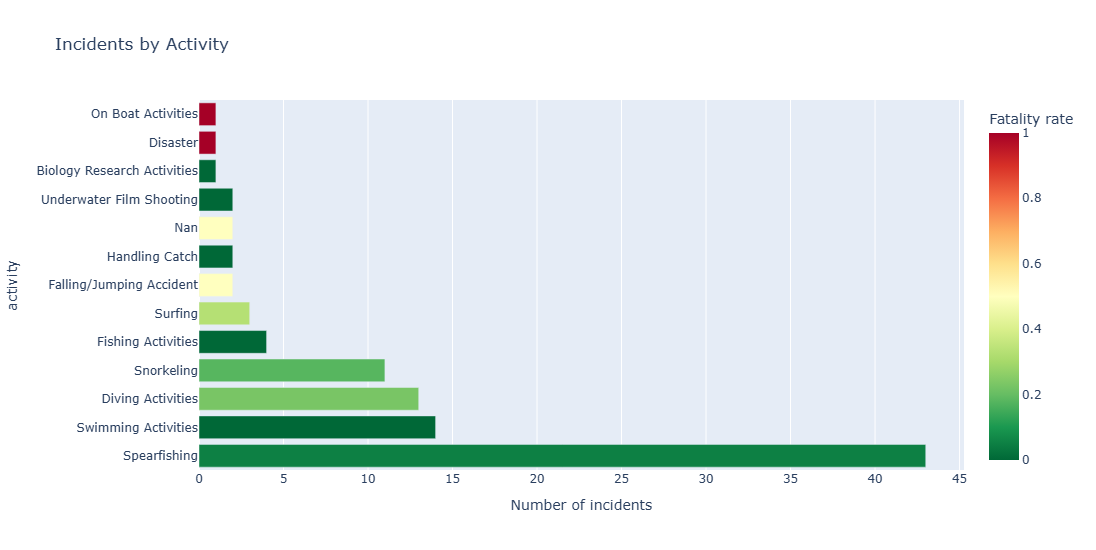

In [120]:
#this pivot table shows the type of incident (and inside fatal and severe) per activities
pivot_activity = (jaws
    .groupby("activity")
    .agg(incidents=("date", "count"),
         fatals=("fatality", lambda s: (s == "Fatal").sum()),
         severe=("severity", lambda s: s.isin(["Severe", "Fatal"]).sum()))
    .assign(fatal_rate=lambda d: d["fatals"] / d["incidents"]).round(2)
    .sort_values("incidents", ascending=False))

display(pivot_activity)
# and this is a graphical presentation 
fig = px.bar(pivot_activity.reset_index(),
             x="incidents", y="activity", orientation="h",
             color="fatal_rate", color_continuous_scale="RdYlGn_r",
             hover_data={"fatals": True},
             labels={"incidents": "Number of incidents", "fatal_rate": "Fatality rate"},
             title="Incidents by Activity")
fig.update_layout(height=550)
fig.show()

,incidents,fatals,severe,fatalsandsevere_pct
species,,,,
Unidentified Shark,46,9,7,0.28
Bull Shark,17,2,1,0.18
Reef Shark,14,0,1,0.07
Lemon Shark,6,0,1,0.17
Blacktip Shark,5,0,0,0.00
Nurse Shark,5,0,0,0.00
Tiger Shark,4,1,1,0.25
Shortfin Mako Shark,1,0,0,0.00
White Shark,1,0,1,1.00


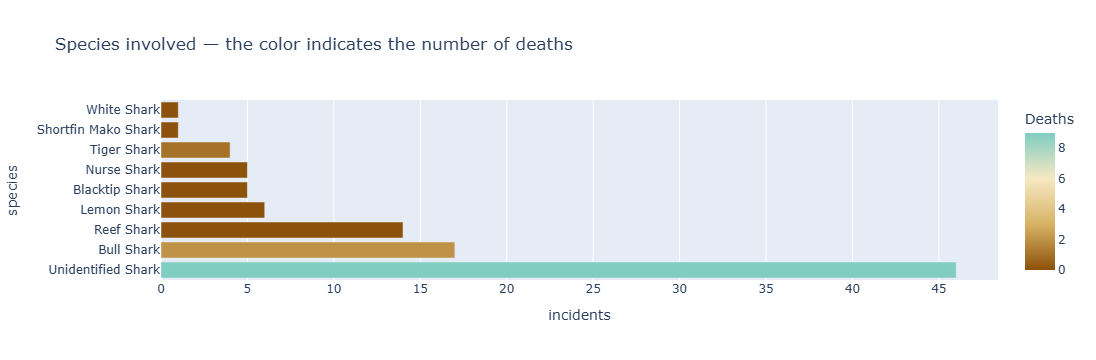

In [121]:
#This pivot table ranks the species per incident (includes fatality and severity)
pivot_species = (jaws
    .groupby("species", dropna=False)
    .agg(incidents=("date", "count"),
         fatals=("fatality", lambda s: (s == "Fatal").sum()),
         severe=("severity", lambda s: (s == "Severe").sum()),
         fatalsandsevere_pct=("severity", lambda s: s.isin(["Severe", "Fatal"]).mean().round(2)))
    .sort_values(["incidents", "fatals"], ascending=False))
display(pivot_species)
# and shows this in a barchart
fig = px.bar(pivot_species.reset_index(),
             x="incidents", y="species", orientation="h",
             color="fatals", color_continuous_scale=["#8c510a", "#d8b365", "#f6e8c3", "#80cdc1"],
             hover_data={"fatal_rate": ":.1%"} if "fatal_rate" in pivot_species.columns
                        else {"fatalsandsevere_pct": ":.1%"}, # in case of non fatal case, shows the severity
             labels={"fatals": "Deaths"},
             title="Species involved — the color indicates the number of deaths")
fig.show()


month_name,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
activity,,,,,,,,,,,,
Biology Research Activities,0,0,0,0,1,0,0,0,0,0,0,0
Disaster,0,0,0,0,1,0,0,0,0,0,0,0
Diving Activities,1,3,0,0,0,1,5,0,0,2,1,0
Falling/Jumping Accident,0,0,0,1,1,0,0,0,0,0,0,0
Fishing Activities,0,0,1,1,0,0,0,0,0,0,1,1
Handling Catch,0,0,1,0,0,0,1,0,0,0,0,0
Nan,0,0,0,0,0,1,0,1,0,0,0,0
On Boat Activities,0,0,0,0,0,0,0,1,0,0,0,0
Snorkeling,1,0,0,0,0,3,3,2,1,1,0,0


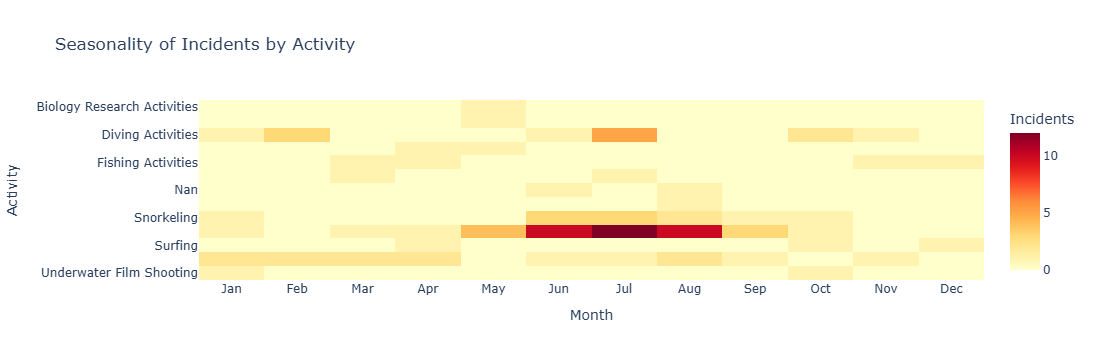

In [122]:
#this pivot shows the seasonality of attacks per type of activities
pivot_month = (jaws
    .dropna(subset=["month"])#excludes NaN
    .groupby(["activity", "month_name"])
    .size()# counts the number of line of each group, including null
    .unstack(fill_value=0)) #put the mounth as a column
pivot_month = pivot_month.reindex(columns=month_order, fill_value=0) #reindex the columns up to the calendar order (not alphabetical)
display(pivot_month)
# this chart shows a heatmap 
fig = px.imshow(pivot_month.values,
                x=pivot_month.columns, y=pivot_month.index,
                color_continuous_scale="YlOrRd", aspect="auto",
                labels=dict(x="Month", y="Activity", color="Incidents"),
                title="Seasonality of Incidents by Activity")
fig.show()

In [123]:

# this pivot table shows incident per state (group of islands)
pivot_state = (jaws
    .dropna(subset=["state"])#excludes NaN
    .query("state != 'UNDEFINED'")#excludes Undefined
    .groupby(["state", "activity"])
    .size()# counts the number of line of each group, including null
    .unstack(fill_value=0))# put the activity in column
display(pivot_state)

activity,Biology Research Activities,Disaster,Diving Activities,Falling/Jumping Accident,Fishing Activities,Handling Catch,Nan,On Boat Activities,Snorkeling,Spearfishing,Surfing,Swimming Activities,Underwater Film Shooting
state,,,,,,,,,,,,,
ABACO ISLANDS,0,0,2,0,0,0,0,0,2,25,1,2,0
ANDROS ISLANDS,0,0,1,0,1,0,0,0,0,2,0,1,0
BERRY ISLANDS,0,0,0,0,0,0,0,0,1,3,0,0,0
BIMINI ISLANDS,1,0,2,0,0,0,0,0,0,2,0,4,0
CAT ISLAND,0,0,1,0,0,0,0,0,0,0,0,0,1
ELEUTHERA ISLAND,0,0,0,0,2,0,0,0,0,2,0,0,0
EXUMA ISLANDS,0,0,0,0,0,2,1,0,2,2,0,5,0
GRAND BAHAMA ISLAND,0,1,7,0,0,0,0,0,1,7,0,1,0
LONG ISLAND,0,0,0,1,0,0,0,0,0,0,0,0,0


lat    float64
lon    float64
dtype: object

np.int64(0)

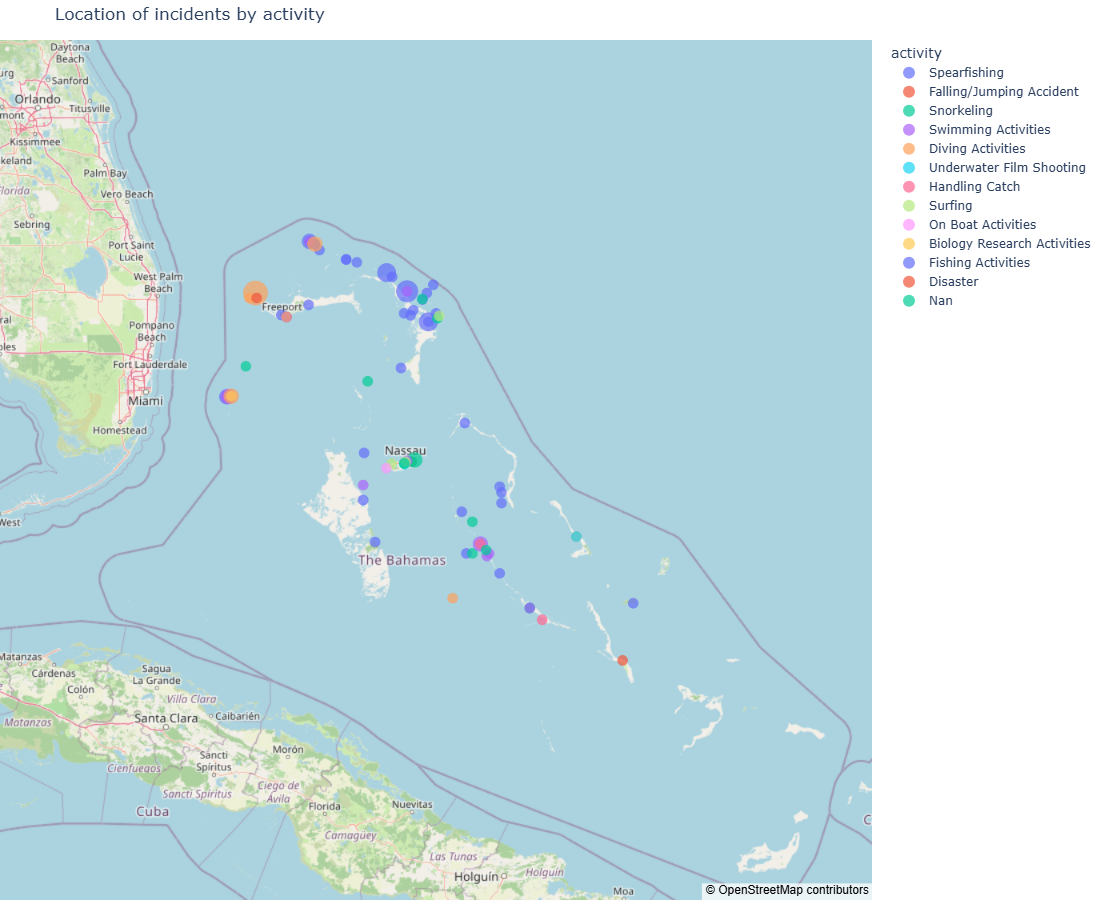

In [124]:
display(jaws[["lat","lon"]].dtypes)# to check if values are numerical
site_counts = (jaws.dropna(subset=["lat", "lon"]) # eliminate non geocoded location
               .groupby(["location", "lat", "lon", "activity"])
               .size().reset_index(name="incidents"))# each point has a number of incident 
display (jaws["lat"].isna().sum()) # to count point without geolocation
#shows in a map with the dispersion of incidents/activities
fig = px.scatter_map(site_counts, lat="lat", lon="lon",
                        size="incidents", size_max=18,# max size 18px
                        color="activity",#each activity has a color
                        hover_name="location", hover_data={"incidents": True},# by pointing the mouse, gives an overview (activity/location/ incident)
                        zoom=6, center={"lat": 25.0, "lon": -77.0},# centering on the Bahamas
                        map_style="open-street-map",# used map, free and no token
                        title="Location of incidents by activity")
fig.update_layout(height=900, width= 1000, margin={"r": 0, "t": 40, "l": 0, "b": 0})
fig.show()

,geocode_input,lat,lon,geo_precision,incidents,fatals
0,10 MILES WEST OF WALKER’S CAY,27.254632,-78.390115,site,1,0
1,ABACO ISLANDS,26.466665,-77.083333,island,4,0
2,ALLAN-PENSACOLA CAY,27.050000,-77.870000,site,1,0
3,AMBERGRIS CAY,25.170000,-77.790000,site,1,0
4,ATHOL ISLAND,25.083333,-77.266666,site,2,1
...,...,...,...,...,...,...
61,TIGER BEACH,26.750000,-78.983002,site,5,2
62,TREASURE CAY,26.750000,-77.100000,site,1,0
63,WALKERS CAY,27.254632,-78.390115,site,3,0
64,WELLS CAY,24.166700,-76.600000,site,1,0


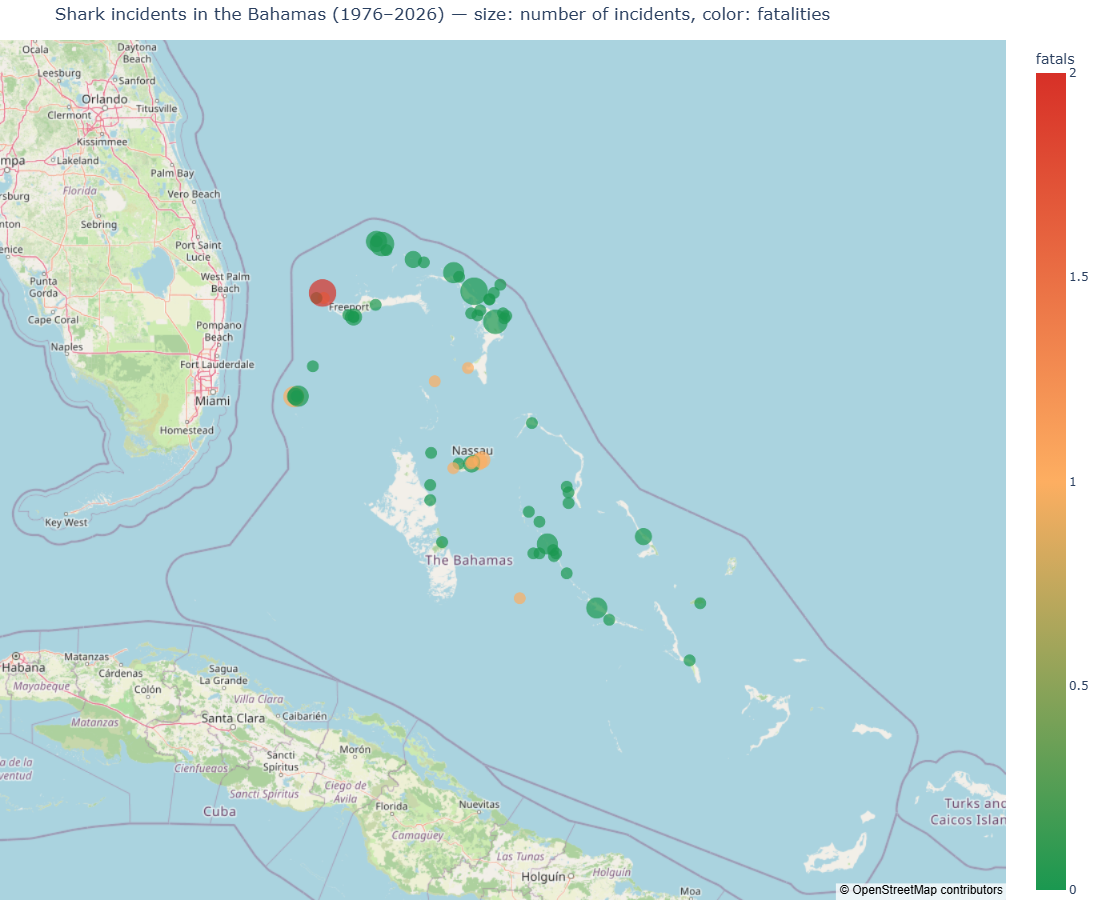

In [125]:
site_counts = (jaws.dropna(subset=["lat"])
               .groupby(["geocode_input", "lat", "lon", "geo_precision"])
               .agg(incidents=("date", "count"),
                    fatals=("fatality", lambda s: (s == "Fatal").sum()))
               .reset_index())
display(site_counts)

#shows in a map with the dispersion of incident/fatality
fig = px.scatter_map(
    site_counts,
    lat="lat", lon="lon",
    size="incidents",
    size_max=20,
    color="fatals",
    color_continuous_scale=["#1a9850", "#fdae61", "#d73027"],
    hover_name="geocode_input",
    hover_data={"incidents": True, "fatals": True,
                "geo_precision": True,
                "lat": ":.3f", "lon": ":.3f"},
    zoom=6, center={"lat": 25.0, "lon": -77.0},
    map_style="open-street-map",
)
fig.update_layout(height=900, width=900, margin={"r": 0, "t": 40, "l": 0, "b": 0},
                  title="Shark incidents in the Bahamas (1976–2026) — size: number of incidents, color: fatalities")
fig.show()

,incidents,fatals,fatal_rate
time,,,
Day,97,11,0.11
Night,2,1,0.50


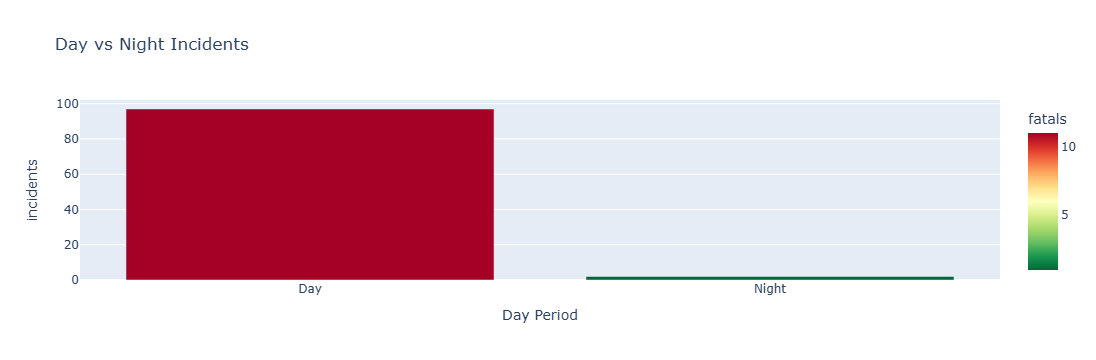

In [126]:
# this pivot and barshart represent the mortality day/night

pivot_time = (jaws
    .dropna(subset=["time"])
    .groupby("time")
    .agg(incidents=("date", "count"),
         fatals=("fatality", lambda s: (s == "Fatal").sum()))
    .assign(fatal_rate=lambda d: d["fatals"] / d["incidents"]).round(2))
display(pivot_time)
fig = px.bar(pivot_time.reset_index(), x="time", y="incidents",
             color="fatals", color_continuous_scale="RdYlGn_r",
             labels={"time": "Day Period"}, title="Day vs Night Incidents")
fig.show()